In [102]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from scipy import stats


# Data preprocessing
### Includes any change made to the data before applying feature selection: imputation, normalisation, bootstrapping,

Process for CW1 went as follows:

Classification
1. One hot encoding (categorical features to binary) | Imputation (using mode, old method) 
Note: there were null values '?' that were not handled before one hot encoding
2. Normalisation (MinMax, numerical features -> 0-1 range)

Regression
1. Imputation (removed null data, mean for continuous, mode for categorical)
2. Normalisation (MinMax)
3. One hot encoding (pd.get_dummies)

Possible other methods for preprocessing include:
- Removing outliers
- VAE/Bootstrapping
    - Generating new instances from not a lot of data
        - Training data after removing outliers

And some more implicit methods include:
- Separating data into features and outcomes/labels

In [103]:
# viewing data and datatypes (numerical / categorical)
dataset = pd.read_csv("./datasets/TrainDataset2025.csv")

dataset.info()
dataset.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Columns: 121 entries, ID to original_ngtdm_Strength
dtypes: float64(108), int64(12), object(1)
memory usage: 378.3+ KB


,ID,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,TRG002174,1,144.0,41.0,0,0,0,1,3,3,...,0.517172,0.375126,3.325332,0.002314,3880771.500,473.464852,0.000768,0.182615,0.030508,0.000758
1,TRG002178,0,142.0,39.0,1,1,0,0,3,3,...,0.444391,0.444391,3.032144,0.005612,2372009.744,59.459710,0.004383,0.032012,0.001006,0.003685
2,TRG002204,1,135.0,31.0,0,0,0,1,2,1,...,0.534549,0.534549,2.485848,0.006752,1540027.421,33.935384,0.007584,0.024062,0.000529,0.006447
3,TRG002206,0,12.0,35.0,0,0,0,1,3,3,...,0.506185,0.506185,2.606255,0.003755,6936740.794,46.859265,0.005424,0.013707,0.000178,0.004543
4,TRG002210,0,109.0,61.0,1,0,0,0,2,1,...,0.462282,0.462282,2.809279,0.006521,1265399.054,39.621023,0.006585,0.034148,0.001083,0.005626


In [104]:
# Split data into features and outcomes

## Outcomes
dataset_y_clf = dataset['pCR (outcome)']
dataset_y_reg = dataset['RelapseFreeSurvival (outcome)']
dataset_y = pd.concat([dataset_y_clf, dataset_y_reg], ignore_index=True, sort=False, axis=1)

## Features
dataset_x_all = dataset.drop(['pCR (outcome)', 'RelapseFreeSurvival (outcome)'], axis=1)

dataset_x_all

,ID,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,TRG002174,41.0,0,0,0,1,3,3,1,1,...,0.517172,0.375126,3.325332,0.002314,3.880772e+06,473.464852,0.000768,0.182615,0.030508,0.000758
1,TRG002178,39.0,1,1,0,0,3,3,1,1,...,0.444391,0.444391,3.032144,0.005612,2.372010e+06,59.459710,0.004383,0.032012,0.001006,0.003685
2,TRG002204,31.0,0,0,0,1,2,1,1,0,...,0.534549,0.534549,2.485848,0.006752,1.540027e+06,33.935384,0.007584,0.024062,0.000529,0.006447
3,TRG002206,35.0,0,0,0,1,3,3,1,1,...,0.506185,0.506185,2.606255,0.003755,6.936741e+06,46.859265,0.005424,0.013707,0.000178,0.004543
4,TRG002210,61.0,1,0,0,0,2,1,1,0,...,0.462282,0.462282,2.809279,0.006521,1.265399e+06,39.621023,0.006585,0.034148,0.001083,0.005626
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,TRG002948,58.5,1,0,1,0,3,2,1,1,...,0.476493,0.476493,2.453583,0.003229,2.327038e+06,18.562377,0.013766,0.018042,0.000288,0.012257
396,TRG002954,34.3,0,0,0,1,3,3,1,0,...,0.418382,0.418382,2.995603,0.004243,1.005061e+06,156.627179,0.002228,0.136015,0.022148,0.002098
397,TRG002958,53.3,0,0,0,1,2,1,1,0,...,0.527779,0.527778,1.500000,0.003728,2.132007e+05,0.996746,0.252582,0.007380,0.000037,0.231059
398,TRG002961,68.8,1,0,0,0,3,3,1,1,...,0.313693,0.313693,3.573557,0.001112,2.008034e+07,204.864200,0.001372,0.054063,0.003697,0.001368


## Type-specific preprocessing
### Dataset datatypes include: object, float64 and int64
    # object: ID Column
    # float64: Continuous features
    # int64: Categorical features

### Handling object datatype
1. Remove object datatype

This only contains the ID column

In [105]:
# Handling object datatype
print(dataset_x_all.select_dtypes(object)) # ID Column

print("Before: "+str(dataset_x_all.select_dtypes(object).shape))

dataset_x_all = dataset_x_all.drop("ID",axis=1)
print("After: "+str(dataset_x_all.select_dtypes(object).shape))


            ID
0    TRG002174
1    TRG002178
2    TRG002204
3    TRG002206
4    TRG002210
..         ...
395  TRG002948
396  TRG002954
397  TRG002958
398  TRG002961
399  TRG002962

[400 rows x 1 columns]
Before: (400, 1)
After: (400, 0)


### Handling int64 datatype
#### Categorical Features
1. Remove non-categorical features

'original_shape_VoxelVolume' feature is int, but not categorical data (doesn't use classes)

Truncate Age feature to make it consistent with other clinical features

In [106]:
print(dataset_x_all.select_dtypes(np.int64))

print("Before: "+str(dataset_x_all.select_dtypes(np.int64).shape))

dataset_x_all['Age'] = dataset_x_all['Age'].astype(np.int64)

dataset_x_all['original_shape_VoxelVolume'] = dataset_x_all['original_shape_VoxelVolume'].astype(np.float64)


print("After: "+str(dataset_x_all.select_dtypes(np.int64).shape))

# Save column names of categorical features for later
categorical_names = dataset_x_all.select_dtypes(np.int64).columns
categorical_names

     ER  PgR  HER2  TrippleNegative  ChemoGrade  Proliferation  HistologyType  \
0     0    0     0                1           3              3              1   
1     1    1     0                0           3              3              1   
2     0    0     0                1           2              1              1   
3     0    0     0                1           3              3              1   
4     1    0     0                0           2              1              1   
..   ..  ...   ...              ...         ...            ...            ...   
395   1    0     1                0           3              2              1   
396   0    0     0                1           3              3              1   
397   0    0     0                1           2              1              1   
398   1    0     0                0           3              3              1   
399   1    0     0                0           2              1              1   

     LNStatus  TumourStage 

Index(['Age', 'ER', 'PgR', 'HER2', 'TrippleNegative', 'ChemoGrade',
       'Proliferation', 'HistologyType', 'LNStatus', 'TumourStage', 'Gene'],
      dtype='object')

### Handling float64 datatype
#### Continuous Features

Nothing specific left, data is all continuous

In [107]:
# Save column names of continuous features for later
dataset_x_all.select_dtypes(np.float64)
continuous_names = dataset_x_all.select_dtypes(np.float64).columns
continuous_names

Index(['original_shape_Elongation', 'original_shape_Flatness',
       'original_shape_LeastAxisLength', 'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_Maximum3DDiameter', 'original_shape_MeshVolume',
       'original_shape_MinorAxisLength',
       ...
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_glszm_SmallAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneEntropy', 'original_glszm_ZonePercentage',
       'original_glszm_ZoneVariance', 'original_ngtdm_Busyness',
       'original_ngtdm_Coarseness', 'original_ngtdm_Complexity',
       'original_ngtdm_Contrast', 'original_ngtdm_Strength'],
      dtype='object', length=107)

## General Preprocessing
1. Null handling (converting '999')
5. Balancing data (Frequency handling)
2. Train-test split
3. Outlier handling
4. Data Imputation
6. One-hot Encoding

### 1. Null Handling
Issue: Can't replace all '999' with np.nan. This converts int64 to float64 as NaN is float64
- Solution: by saving column names, in datatype-specific handling, for int64 (categorical) features, no longer a need to preserve int64 as no data is lost when converting to float

In [108]:
# Replace 999 (placeholder) with actual null values
dataset_x_all = dataset_x_all.replace([999],np.nan)

# Viewing features with null values
non_null = dataset_x_all.isnull().sum()
non_null = non_null[non_null > 0]
non_null

PgR                 1
HER2                1
TrippleNegative     1
ChemoGrade          3
Proliferation       2
HistologyType       3
LNStatus            1
Gene               88
dtype: int64

### 2. Train-test split

In [109]:
# Split the X_train into 80% for training data and 20% for test data with stratified splitting to keep the balance of 0 and 1 classes in the training and test sets roughly the same
X_train, X_test, y_train, y_test = train_test_split(dataset_x_all, dataset_y_clf, test_size = 0.2, random_state = 12, stratify = dataset_y_clf)

### 3. Outlier Removal
Options: 
1. Z-Score
2. Interquartile Range

[Other Model-based methods:](https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/)

3. Isolation Forest
4. Local Outlier Factor
5. DBSCAN(?)

[Even More Model-based Methods](https://scikit-learn.org/stable/modules/outlier_detection.html#:~:text=OK-,2.7.1.%20Overview%20of%20outlier%20detection%20methods,-%23)

<Axes: >

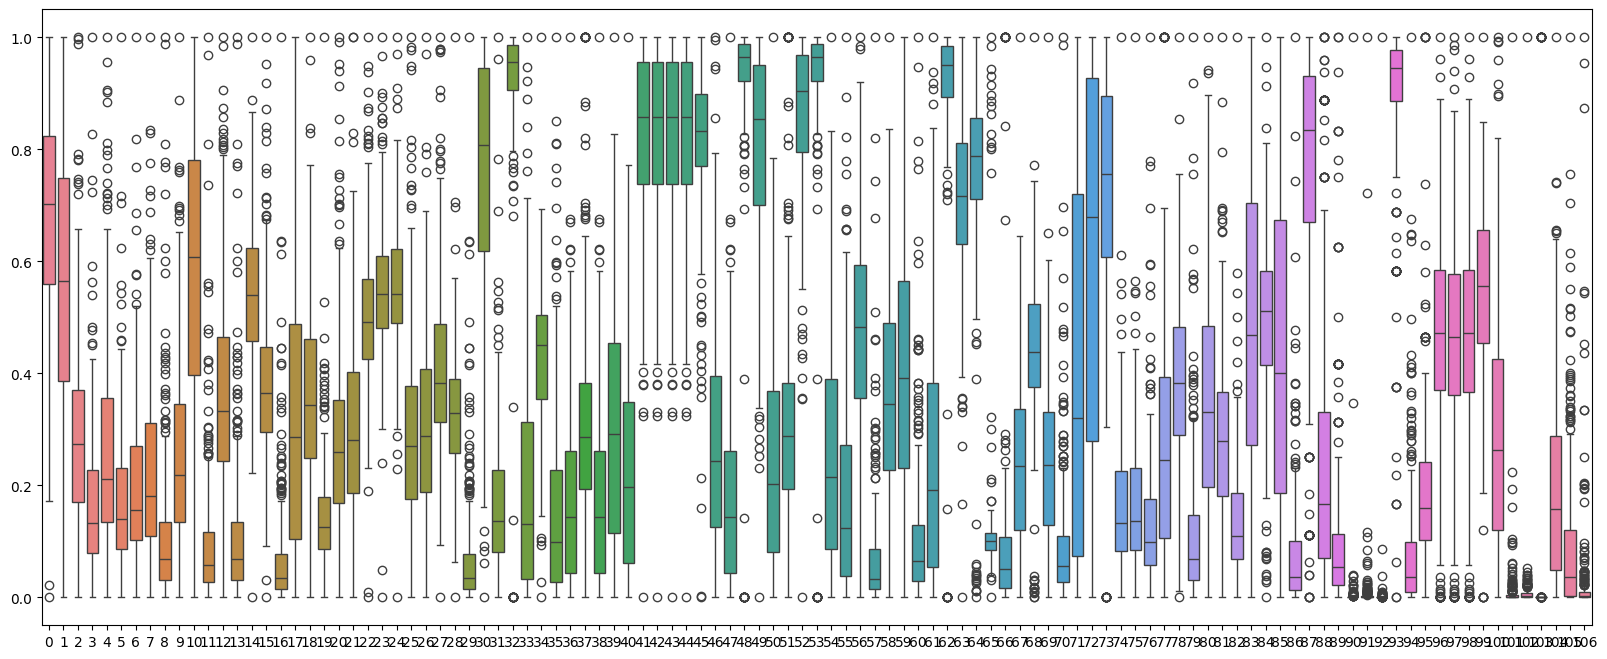

In [110]:
# Data visualisation
scaler = MinMaxScaler()

# Boxplot below shows normalised continuous features + outliers
fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=scaler.fit_transform(X_train[continuous_names]),ax=ax)

Note: Above boxplot, categorical features normalised to 0-1 range, shows prevalence of outliers. Handling using naive methods, such as Z-score or IQR, may be ineffective

##### Option 1 - Z-score

In [111]:
# Printing outlier locations
z_scores = np.abs(stats.zscore(X_train))
outliers_zscore = np.where(z_scores > 3)
outlier_indices = list(zip(outliers_zscore[0], outliers_zscore[1]))

print("Outlier total: "+str(len(outlier_indices)))
for index in outlier_indices:
    print(index)

Outlier total: 525
(np.int64(9), np.int64(13))
(np.int64(9), np.int64(16))
(np.int64(9), np.int64(17))
(np.int64(9), np.int64(18))
(np.int64(9), np.int64(19))
(np.int64(9), np.int64(22))
(np.int64(9), np.int64(24))
(np.int64(9), np.int64(27))
(np.int64(9), np.int64(31))
(np.int64(9), np.int64(36))
(np.int64(9), np.int64(40))
(np.int64(9), np.int64(71))
(np.int64(9), np.int64(81))
(np.int64(9), np.int64(90))
(np.int64(9), np.int64(112))
(np.int64(35), np.int64(43))
(np.int64(35), np.int64(48))
(np.int64(35), np.int64(59))
(np.int64(35), np.int64(62))
(np.int64(35), np.int64(64))
(np.int64(35), np.int64(73))
(np.int64(35), np.int64(75))
(np.int64(35), np.int64(76))
(np.int64(35), np.int64(77))
(np.int64(35), np.int64(79))
(np.int64(35), np.int64(84))
(np.int64(35), np.int64(87))
(np.int64(35), np.int64(88))
(np.int64(35), np.int64(95))
(np.int64(35), np.int64(106))
(np.int64(35), np.int64(110))
(np.int64(35), np.int64(114))
(np.int64(45), np.int64(39))
(np.int64(52), np.int64(15))
(np.in

In [112]:
# Applying z-score

X_train[(np.abs(stats.zscore(X_train)) < 3).all(axis=1)] # < 3 checks for rows where all features are 3 standard deviations from the mean

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength


Note: Z-score is clearly ineffective. Implication from above cell is that outliers are prevalent in all samples, hence they are all removed

##### Option 2 - Interquartile Range

In [113]:
# Calculating Interquartile Range
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1

In [114]:
# Outputting number of outliers per column
outliers_iqr = ((X_train < (Q1 - 1.5 * IQR)) | (X_train > (Q3 + 1.5 * IQR)))

print("Number of outliers per column:")
outliers_col = outliers_iqr.sum()
outliers_col = outliers_col[outliers_col > 0]

print(outliers_col)

Number of outliers per column:
HistologyType                             43
original_shape_Elongation                  2
original_shape_LeastAxisLength            10
original_shape_MajorAxisLength            11
original_shape_Maximum2DDiameterColumn    15
                                          ..
original_ngtdm_Busyness                   28
original_ngtdm_Coarseness                 49
original_ngtdm_Complexity                  6
original_ngtdm_Contrast                   32
original_ngtdm_Strength                   48
Length: 100, dtype: int64


In [115]:
# Applying IQR (incomplete)
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

upper_arr = np.where(X_train >= upper)[0]
lower_arr = np.where(X_train <= lower)[0]

# X_train.drop(index=upper_arr, inplace=True)
# X_train.drop(index=lower_arr, inplace=True)

##### Option 2.5 - Combine Z-score and IQR

Both methods fail to work independently, but together provides differing results

Before


<Axes: >

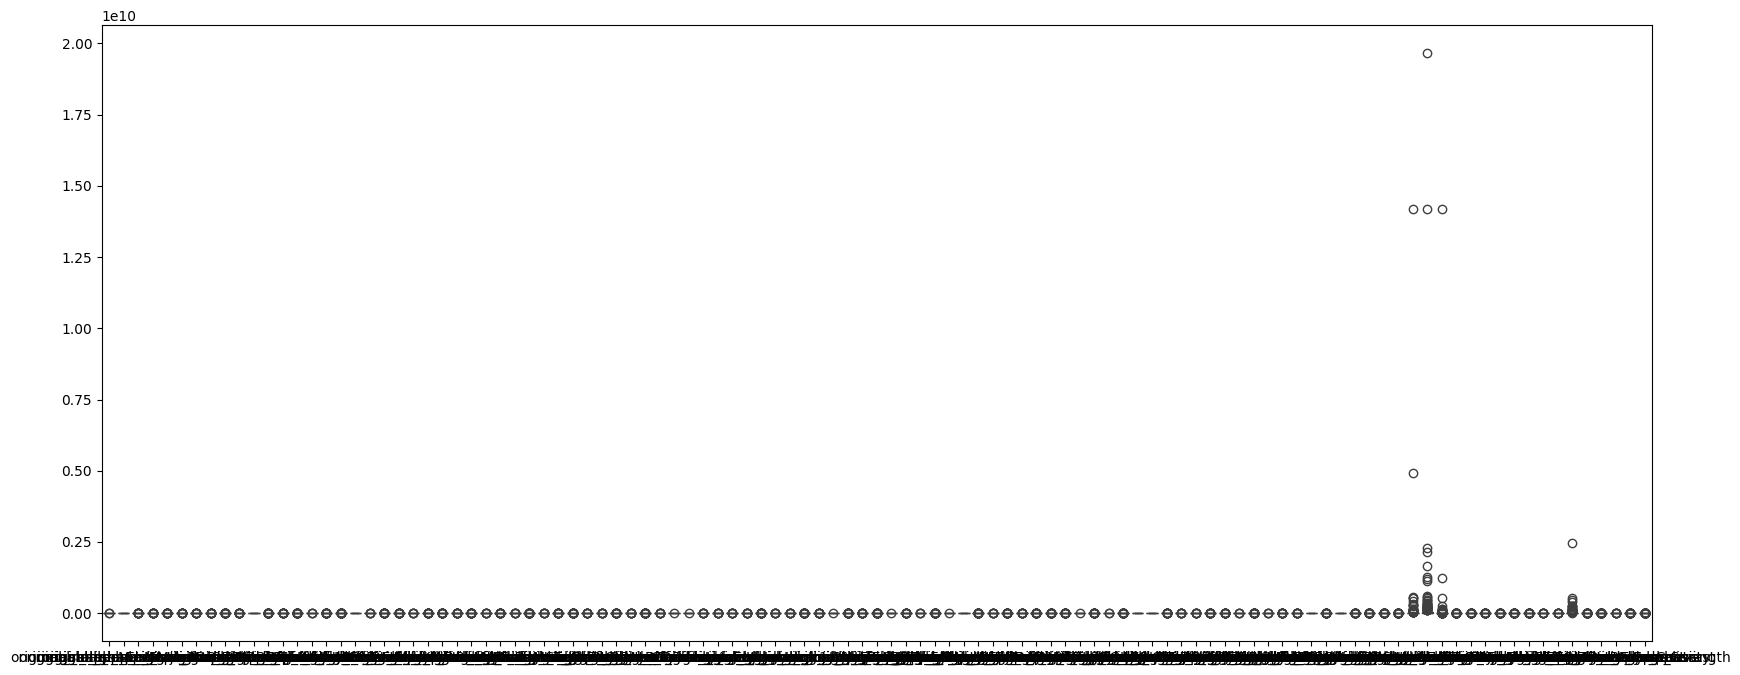

In [116]:
print("Before")
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

In [117]:
# Handle outliers in columns of continuous features using Interquartile Range of the columns
for col in continuous_names:
    lower_quartile = X_train[col].quantile(0.25)
    upper_quartile = X_train[col].quantile(0.75)
    iqr = upper_quartile - lower_quartile

    lower_bound = lower_quartile - 1.5 * iqr
    upper_bound = upper_quartile + 1.5 * iqr
    
    X_train[col] = np.where((X_train[col] < lower_bound) | (X_train[col] > upper_bound), X_train[col].median(), X_train[col])


In [118]:
# Printing outlier locations
z_scores = np.abs(stats.zscore(X_train))
outliers_zscore = np.where(z_scores > 3)
outlier_indices = list(zip(outliers_zscore[0], outliers_zscore[1]))

print("Outlier total: "+str(len(outlier_indices)))
for index in outlier_indices:
    print(index)

Outlier total: 175
(np.int64(8), np.int64(73))
(np.int64(8), np.int64(77))
(np.int64(10), np.int64(19))
(np.int64(10), np.int64(24))
(np.int64(13), np.int64(81))
(np.int64(21), np.int64(105))
(np.int64(24), np.int64(114))
(np.int64(27), np.int64(68))
(np.int64(40), np.int64(97))
(np.int64(41), np.int64(114))
(np.int64(42), np.int64(102))
(np.int64(42), np.int64(112))
(np.int64(48), np.int64(27))
(np.int64(48), np.int64(40))
(np.int64(48), np.int64(117))
(np.int64(51), np.int64(75))
(np.int64(58), np.int64(22))
(np.int64(58), np.int64(81))
(np.int64(67), np.int64(114))
(np.int64(69), np.int64(101))
(np.int64(69), np.int64(102))
(np.int64(70), np.int64(105))
(np.int64(75), np.int64(117))
(np.int64(76), np.int64(19))
(np.int64(76), np.int64(71))
(np.int64(78), np.int64(117))
(np.int64(83), np.int64(68))
(np.int64(83), np.int64(112))
(np.int64(84), np.int64(81))
(np.int64(84), np.int64(100))
(np.int64(84), np.int64(104))
(np.int64(86), np.int64(68))
(np.int64(90), np.int64(100))
(np.int64(

##### Option 3 - Isolation Forest
Method of anomaly detection that isolates outliers by building decision trees based on multiple splits. Supposedly better for high dimensions [[reference]](https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/#:~:text=IQR%20Method-,3.%20Isolation%20Forest,-Isolation%20Forest%20is)

Params include: contamination, random state and bootstrap [(among others that may be useful)](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html#:~:text=IsolationForest-,IsolationForest,-%23)
- contamination (float) is the percentage of outliers
- random state (int) is the pseudorandom seed
- bootstrap (bool) is an option to enable random sampling with replacement

In [119]:
# from sklearn.ensemble import IsolationForest

# iso = IsolationForest(contamination=0.05, random_state=42, bootstrap=True)
# y_pred_iso = iso.fit_predict(X_train)

# X_train["IsoForest_Outlier"] = y_pred_iso
# print(X_train["IsoForest_Outlier"].value_counts())

# plt.figure(figsize=(7, 5))
# sns.scatterplot(x="original_shape_Elongation", y=dataset_y_clf, data=X_train,
#                 hue="IsoForest_Outlier", palette="coolwarm")
# plt.title("Isolation Forest Outlier Detection")
# plt.show()

### 3. Data Imputation
Performed after outlier handling as imputation should perform better with clean(er) data, especially for null values

Null values can be removed or imputed, or a combination of both consider only removing Gene null values, as other null totals are [minimal](#1-null-handling)  
- SimpleImputer for imputation by mean/mode/median
- IterativeImputer for model-based imputation

##### SimpleImputer

Options:
1. Removal of all null values
2. Partial Removal, Partial Imputation
3. Imputation of all null values

This has a 'missing_values' field, meaning we could set said field to 999 instead of the earlier conversion of 999 to NaN
- Prefer not to do so as '999' would negatively affect algorithms

##### 1. Removal of all null values
Majority of null values are from one feature ('Gene'). Is it worth removing them all?

In [120]:
# # Removal (entirely)
# X_train = X_train.dropna()

##### 2. Partial Removal, Partial Imputation
1. Removing Gene
2. Imputing other features (format: x|y -> continuous|categorical)

    2.1 Mean|Mode Imputation

    2.2 Mode|Mode Imputation

Impute continuous features using the mean and categorical features using the mode

Removes the majority of outliers ('Gene'), imputes the rest.

In [121]:
imputer_mean = SimpleImputer(strategy='mean')
imputer_mode = SimpleImputer(strategy='most_frequent')

In [122]:
## 1. Removing Gene
X_train['Gene'].dropna()

## 2. Imputing other features (format: x|y -> continuous|categorical)
    
### 2.1 Mean|Mode
X_train[continuous_names] = imputer_mean.fit_transform(X_train[continuous_names])
X_train[categorical_names] = imputer_mode.fit_transform(X_train[categorical_names])

# ### 2.2 Mode|Mode
# X_train[continuous_names] = imputer_mode.fit_transform(X_train[continuous_names])
# X_train[categorical_names] = imputer_mode.fit_transform(X_train[categorical_names])


# Outputting null values: none remaining
non_null = X_train.isnull().sum()
non_null = non_null[non_null > 0]
non_null

Series([], dtype: int64)

##### 3. Imputation of all null values

(format: x|y -> continuous|categorical)
1. Imputing using mean|mode
2. Imputing using the median|mode


Added this case for comparison

Mean|Mode Imputation

In [123]:
# X_train[continuous_names] = imputer_mean.fit_transform(X_train[continuous_names])
# X_train[categorical_names] = imputer_mode.fit_transform(X_train[categorical_names])

Median|Mode Imputation

(Median is less sensitive to outliers than mean)

In [124]:
# For the continuous features, impute the missing values in each column with the median of that column
#median_imputer = SimpleImputer(missing_values = np.nan, strategy = 'median')
#X_train[continuous_names] = median_imputer.fit_transform(X_train[continuous_names])
#X_train[continuous_names].head()

##### IterativeImputer

1. Nearest neighbour imputation (different scales in features may be punishing)

Allows for models to determine imputation

[This](https://scikit-learn.org/stable/modules/impute.html#multiple-vs-single-imputation:~:text=of%20IterativeImputer.-,7.4.3.2.%20Multiple%20vs.%20Single%20Imputation,-%23) might be helpful

### 4. Balancing
We can use stratification when building models to make sure the data is split in the same way as the distribution. We should, therefore, clean up the distribution of data
- Applies for classification as we split based on discrete outcome
- Question: How do we apply to regression?

1. Classification (pCR (outcome))
2. Regression (RelapseFreeSurvival (outcome))

##### 1. Classification (pCR (outcome))
Use a histogram to view relative frequencies

pCR (outcome)
0      311
1       84
999      5
Name: count, dtype: int64


<Axes: xlabel='pCR (outcome)', ylabel='count'>

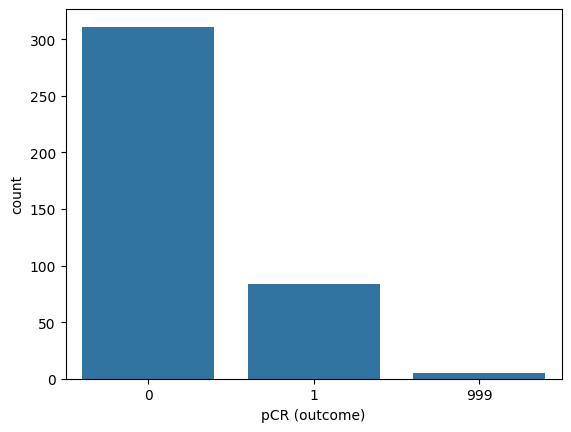

In [125]:
# pCR (outcome) visualisation
print(dataset_y_clf.value_counts())

# sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.countplot(x=dataset_y_clf, data=X_train)

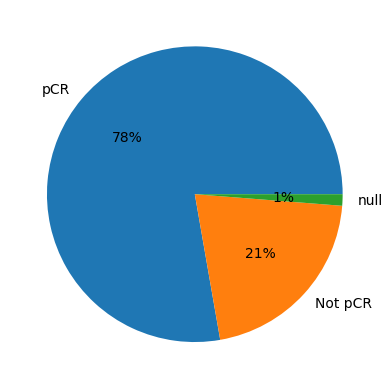

In [126]:
# Pie chart

plt.pie(x=dataset_y_clf.value_counts(), labels=['pCR', 'Not pCR', 'null'], autopct='%.f%%')
plt.show()

### 5.a Normalisation
Options:
1. MinMax
2. Z-normalisation
3. Vector Normalisation
4. More research: https://www.geeksforgeeks.org/python/data-normalization-with-pandas/

##### Before Normalisation

<Axes: >

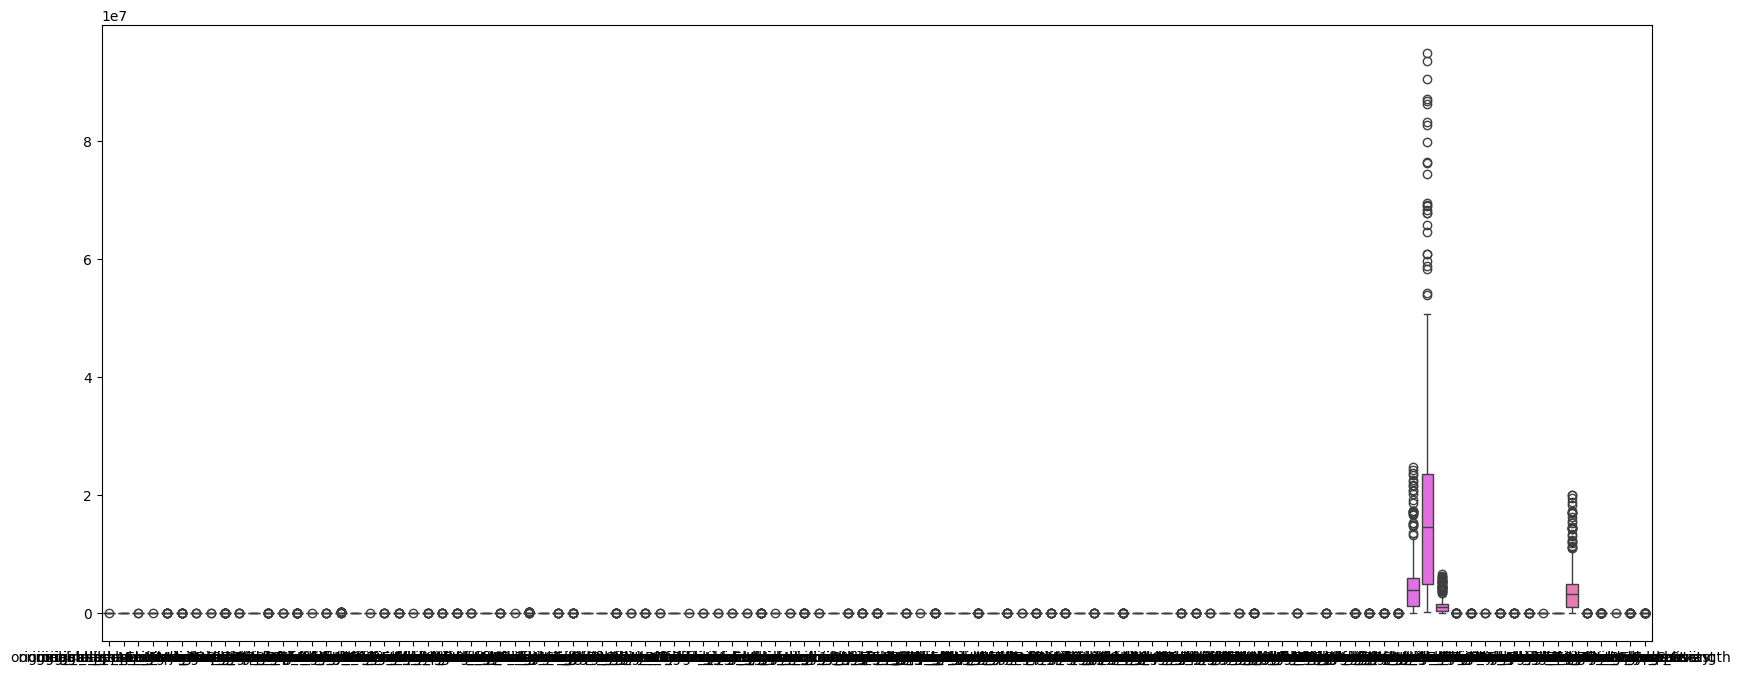

In [127]:
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

##### 1. MinMax

<Axes: >

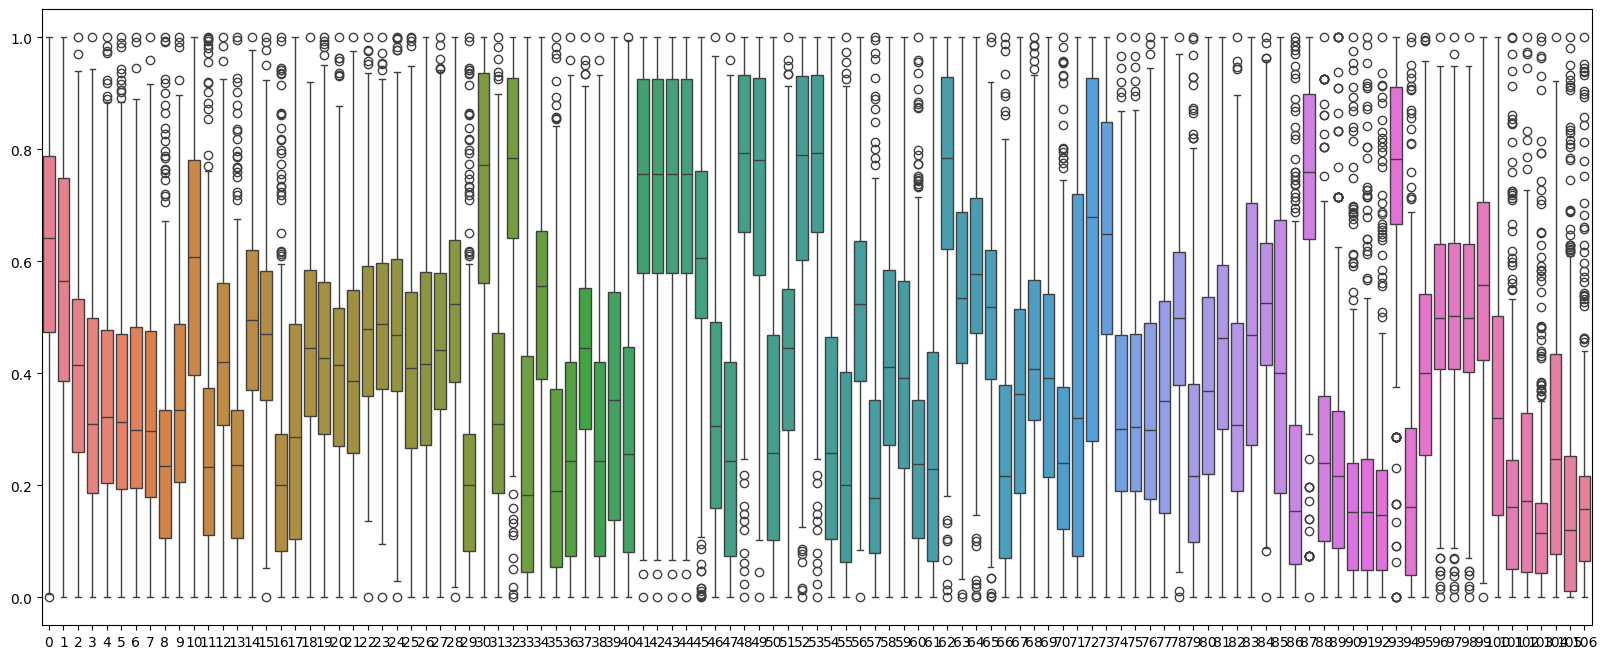

In [128]:
scaler = MinMaxScaler()
# X_train[continuous_names] = scaler.fit_transform(X_train[continuous_names])
# X_train[continuous_names]

fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=scaler.fit_transform(X_train[continuous_names]),ax=ax)

##### 2. Z-normalisation
Better in this use case as we apply PCA later

After


<Axes: >

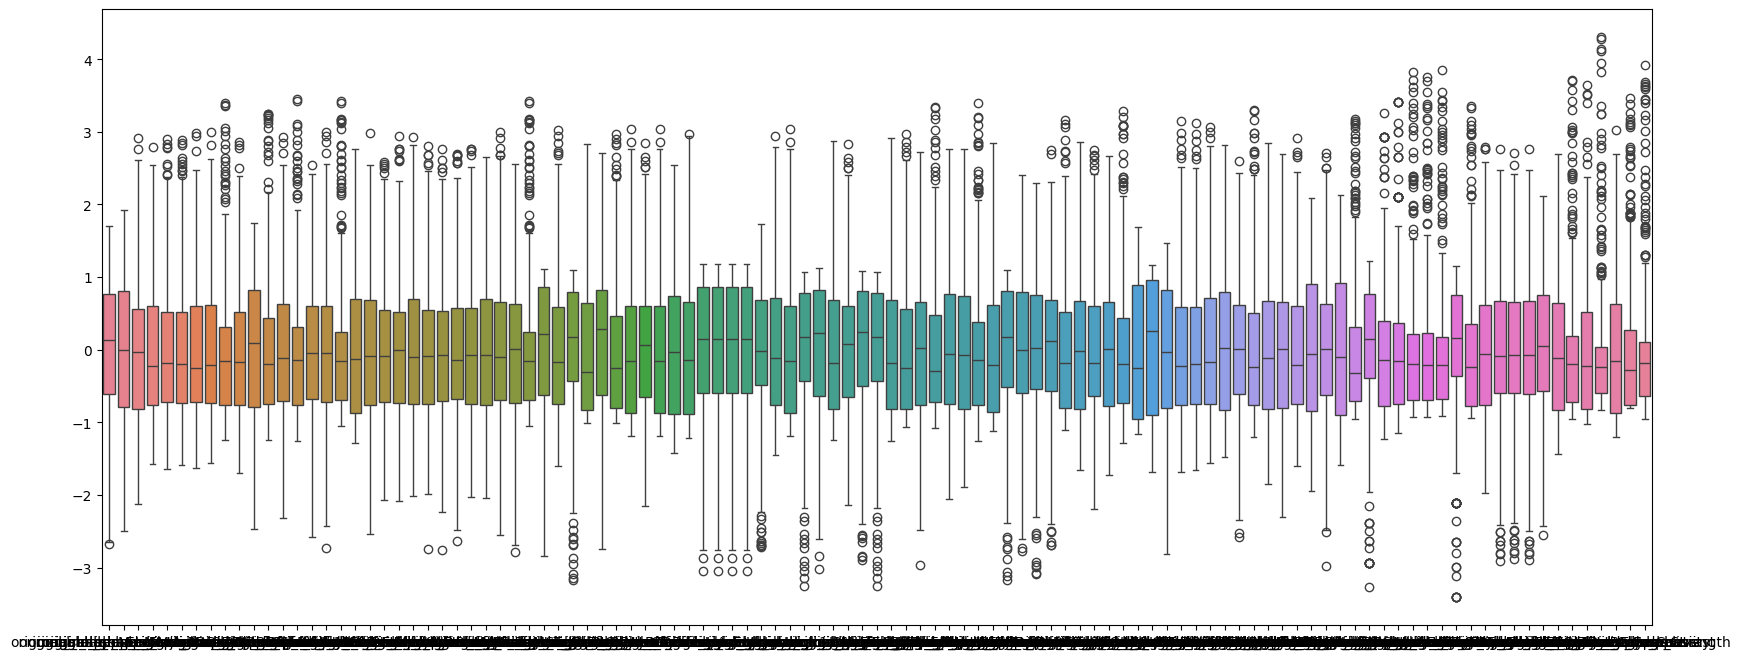

In [129]:
# Apply Z-Score Normalisation to the columns for the continuous features
standard_scaler = StandardScaler()
X_train[continuous_names] = standard_scaler.fit_transform(X_train[continuous_names])

print("After")
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train[continuous_names], ax = ax)

##### 5.b One-hot Encoding

In [130]:
# Apply One-Hot Encoding to the columns for the categorical features
X_train_encoded = pd.get_dummies(X_train, columns = categorical_names, drop_first = True)
X_train_encoded

,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,...,ChemoGrade_2.0,ChemoGrade_3.0,Proliferation_2.0,Proliferation_3.0,HistologyType_2.0,LNStatus_1.0,TumourStage_2.0,TumourStage_3.0,TumourStage_4.0,Gene_1.0
365,-0.331740,-1.218654,0.605033,1.767606,1.732254,1.084528,1.583962,2.171387,-0.126792,1.837382,...,True,False,False,False,False,True,False,True,False,False
172,0.844836,-0.406867,0.200797,0.289656,0.771266,0.517727,0.650198,0.596312,1.346284,0.987050,...,True,False,False,False,False,False,False,True,False,True
183,0.149633,-0.675431,1.286706,1.537853,0.941608,1.443161,1.148711,1.368889,0.314312,2.047252,...,True,False,False,False,False,False,False,True,False,True
299,-0.043448,-0.578264,-0.649736,-0.291573,0.198472,-0.596488,0.249230,-0.091174,-0.696690,-0.246752,...,True,False,False,False,False,True,True,False,False,False
321,-1.058208,-0.597123,-0.306624,0.024097,-0.407554,-0.387664,0.250769,-0.124087,-0.100603,-0.457660,...,True,False,False,False,True,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,0.203652,-0.066449,1.027190,0.625191,1.119891,1.028004,0.830357,0.873276,2.298539,0.988542,...,True,False,False,False,True,True,False,True,False,False
44,-0.286330,0.224132,0.683602,0.156192,-0.102668,0.492230,0.010506,0.512526,1.266558,0.123960,...,True,False,False,False,False,False,True,False,False,True
63,-1.338589,-0.542346,1.972619,1.943043,-0.178589,0.822513,-0.248878,2.569696,-0.154880,0.965092,...,False,True,True,False,True,True,False,True,False,False
388,-0.386060,0.100366,2.503461,1.509147,1.761823,2.122508,0.856480,1.164910,-0.154880,1.506897,...,False,True,True,False,False,True,False,True,False,False


In [131]:
# Check that there are no longer any missing values for the features of each data point
missing_values = X_train_encoded.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

Series([], dtype: int64)

In [132]:
# X_train.to_csv("./datasets/PreProcessedDataset.csv",index=False)

# Feature Selection / Dimensionality reduction
### Note: specification says to keep the following features: 'ER', 'HER2' and 'Gene' 

Feature Selection
- Wrapper methods: forward feature selection, recursive feature elimination
- Embedded methods: LASSO, Decision Trees
- Filter based methods: t-tests, chi square, univariate ANOVA, correlation analysis, idk what else slides say


Dimensionality Reduction
- Includes: PCA, LDA, manifold learning
- Is manifold learning even applicable? 


First do Correlation analysis for visualisation: https://www.geeksforgeeks.org/machine-learning/data-preprocessing-machine-learning-python/#:~:text=Step%205%3A%20Correlation%20Analysis

- Also other methods in lab probably

### Feature Selection
Feature Selection aims to create a subset of the original features optimal for the model building process. This is split into 3 categories.
- Wrapper Methods
- Embedded Methods
- Filter-based Methods

##### Wrapper Methods
These likely take too long as they iterate through different feature permutations and evaluate them using an evaluation metric. Possibly apply after another method that has already reduced the number of features.

Options:
1. Forward Feature Selection
2. Recursive Feature Elimination



##### Embedded Methods
Embed Feature Selection into the model process. Should probably use in the ML Method Development process.

Options:
1. LASSO (Regression)
2. Decision Trees / Random Forest

##### Filter-based Methods
These methods are dependent on the datatypes of features (Xs) and outcomes (ys). Feature datatypes are both categorical and continuous, meaning different methods would have to be applied based on this. The classification outcome, 'pCR (outcome)', is categorical data; meanwhile the regression outcome, 'RelapseFreeSurvival (outcome)', is continuous data.

Options:

- t-test
- chi-square
- ANOVA
- Correlation Analysis

chi-square requirements:
- Categorical Features: dataset contains categorical features
- Categorical Outcome: pCR (outcome) is the categorical outcome

Conclusion: Applicable, features would need to be split

### Dimensionality Reduction
Reduces the dimension of the data by generating new features from the old ones. This reduces interpretability, as new features are not the same as the old ones, hence we lose some understanding of the dataset

##### PCA (Principal Component Analysis)
This unsupervised learning method fits data to a new pair of axes so that it can be split using less features. This is done by calculating the mean (origin of new axes), covariance matrix (ellipse that contains the data), eigenvalues and eigenvectors of the covariance matrix (pair of new axes). 

scikit-learn pca has the following approach:
- n_components is the desired output feature total

In [140]:
from sklearn.decomposition import PCA

pca = PCA(n_components=10)
Xs_pca = pca.fit_transform(X_train)
PCA_df = pd.DataFrame(Xs_pca, columns=['PCA_'+str(i+1) for i in range(Xs_pca.shape[1])])

PCA_df

,PCA_1,PCA_2,PCA_3,PCA_4,PCA_5,PCA_6,PCA_7,PCA_8,PCA_9,PCA_10
0,2.011714,-3.251389,-0.181258,8.549067,-1.011115,-2.571880,2.196710,2.383528,-0.344917,0.084788
1,15.278453,4.409732,6.088998,2.730387,0.851763,-0.488290,-0.042862,-0.466469,1.063332,-0.125406
2,-17.044663,-2.983630,1.906719,5.212290,-0.494352,-1.411610,2.371589,2.642325,-0.468844,-0.774769
3,15.031780,-6.168949,-5.372387,5.167529,-1.108207,1.076273,0.106816,0.000329,1.281920,-0.114487
4,22.191940,3.446395,0.661738,1.091751,3.494696,0.696039,0.094910,-0.707545,-2.508453,-0.550644
...,...,...,...,...,...,...,...,...,...,...
315,5.180093,1.675284,7.549194,2.952221,1.955323,-2.266700,1.588517,-0.489860,1.659277,0.529061
316,-12.993873,0.731837,5.439749,-3.407056,1.972944,1.327657,-0.278179,0.500381,-2.332431,-1.241318
317,-18.848522,3.675863,7.508349,0.042390,-1.586283,5.045399,-2.111382,0.586378,-1.451741,0.507763
318,22.942520,-1.507594,7.008451,-0.171515,0.468246,-0.827473,-1.521491,-0.626793,-1.673122,0.985456


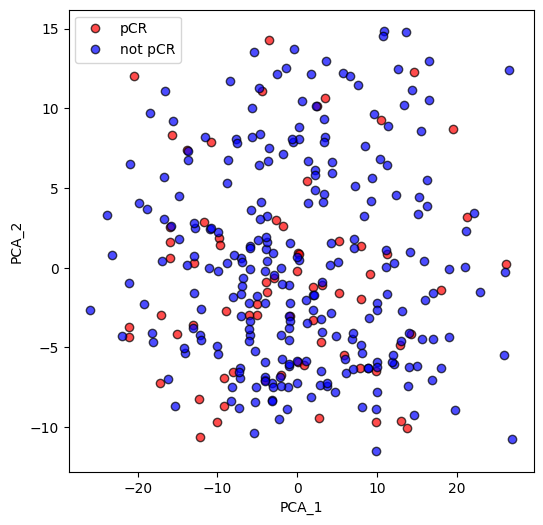

In [141]:
plt.figure(figsize=(6,6))
plt.plot(PCA_df['PCA_1'][dataset_y_clf == 1], PCA_df['PCA_2'][dataset_y_clf == 1], 'ro', alpha = 0.7, markeredgecolor = 'k')
plt.plot(PCA_df['PCA_1'][dataset_y_clf == 0], PCA_df['PCA_2'][dataset_y_clf == 0], 'bo', alpha = 0.7, markeredgecolor = 'k')
plt.xlabel('PCA_1')
plt.ylabel('PCA_2')
plt.legend(['pCR','not pCR'])

##### LDA (Linear Discriminant Analysis)
This supervised learning method projects data to a new pair of axes that helps split it into different classes. This is done by maximising the variance between data of different classes to separate them, and minimising the mean to keep datapoints within the same class together

In [143]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

lda = LDA()
lda.fit(X = X_train, y = y_train)

lda.predict(X=[X_train.loc[1]])

C:\Users\EK\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearDiscriminantAnalysis was fitted with feature names
  warnings.warn(


array([0])